# Titanic Survival Prediction Dataset

1. We will teaching our model to guess whether a Titanic passenger survived, using data like their age, sex, and ticket class.
2. We will show it the passengers whose outcome is already known and then train it to learn the patterns.
3. Then we will test it on the passenger who it hasn't seen and measure how often it is right.

 ## Importing Useful Libraries

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

## Step 1: Load the Data
Loaded the Titanic dataset from seaborn.

In [ ]:
df = sns.load_dataset('titanic')

# Display the first 5 rows
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


## Step 2: Check Missing Values
`age`is missing in '177' rows, `embarked` is missing in '2' rows, `deck` is missing in '688' rows and `embark_town` is missing in '2' rows.

In [ ]:
print(df.shape)
print(df.isnull().sum())

(891, 15)
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


## Step 3: Clean the Data
`deck` is empty in 668 rows (about 77%), which is too empty . So drop it. Fill the age with medium age and fill embarked info with most common value.

In [ ]:
df = df.drop(columns=['deck'])

df['age'] = df['age'].fillna(df['age'].median())

df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

# Check that nothing is missing now
print(df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


## Step 4: Explore the Data by making a chart
Survival count using `sex` and `class`. The chart shows women and 1st class passengers survived at a higher rate than male and 3rd class passengers.

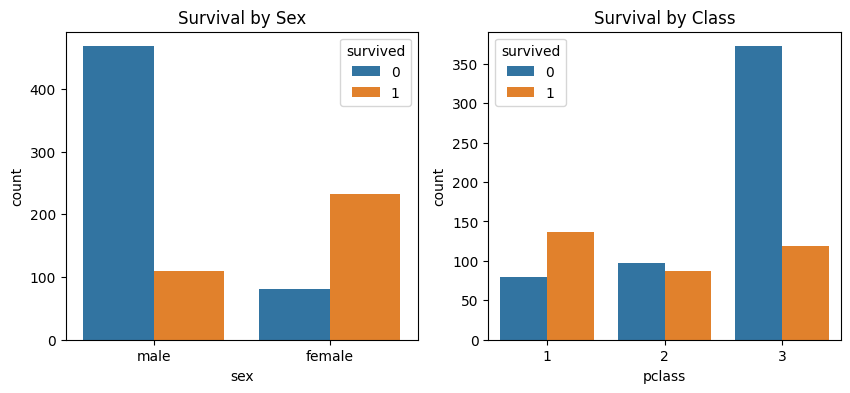

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=df, x='sex', hue='survived', ax=axes[0])
axes[0].set_title('Survival by Sex')

sns.countplot(data=df, x='pclass', hue='survived', ax=axes[1])
axes[1].set_title('Survival by Class')

plt.show()

## Step 5: Convert to numbers and prepare Features
Models only understand numbers, so we convert the information in 0/1 and pick the important features to use.

In [ ]:
# Convert
df['sex'] = df['sex'].map({'male': 0, 'female': 1})

# Choose the input features (X) and the target we want to predict (y)
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']
X = df[features]
y = df['survived']

print(X.head())
print(y.head())

   pclass  sex   age  sibsp  parch     fare
0       3    0  22.0      1      0   7.2500
1       1    1  38.0      1      0  71.2833
2       3    1  26.0      0      0   7.9250
3       1    1  35.0      1      0  53.1000
4       3    0  35.0      0      0   8.0500
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


## Step 6: Train and Evaluate Models
The data is split 70% for training and 30% for testing. Compare Logical Regression and Random Forest on a train/test split.

In [ ]:
# 70/30 split, same random_state so results are repeatable
X_train70, X_test30, y_train70, y_test30 = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# train the model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train70, y_train70)

# evaluate on the test set
y_pred = lr_model.predict(X_test30)
print("Accuracy :", accuracy_score(y_test30, y_pred))
print("Precision:", precision_score(y_test30, y_pred))
print("Recall   :", recall_score(y_test30, y_pred))
print("F1-Score :", f1_score(y_test30, y_pred))

Accuracy : 0.8134328358208955
Precision: 0.8144329896907216
Recall   : 0.7117117117117117
F1-Score : 0.7596153846153846


Random Forest is trained on the same 70/30 split, so the two models can be compared with Logistic Regression.

In [ ]:
# Train Random Forest on the same 70/30 split
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train70, y_train70)

rf_pred = rf_model.predict(X_test30)
print("Random Forest")
print("Accuracy :", accuracy_score(y_test30, rf_pred))
print("Precision:", precision_score(y_test30, rf_pred))
print("Recall   :", recall_score(y_test30, rf_pred))
print("F1-Score :", f1_score(y_test30, rf_pred))

Random Forest
Accuracy : 0.7835820895522388
Precision: 0.7523809523809524
Recall   : 0.7117117117117117
F1-Score : 0.7314814814814815


## Step 7: Confusion Matrix

The confusion matrix shows how many passengers were predicted correctly and incorrectly.

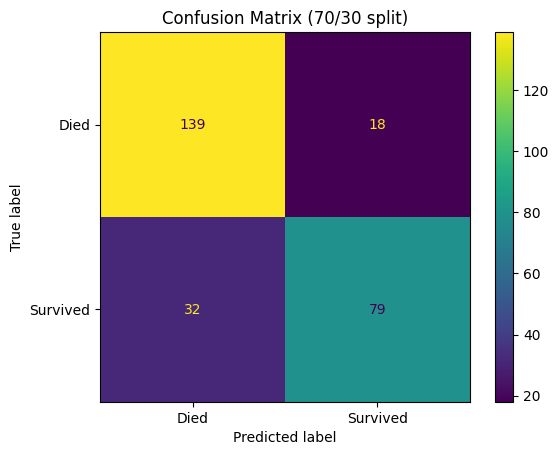

In [ ]:
cm = confusion_matrix(y_test30, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Died', 'Survived']).plot()
plt.title('Confusion Matrix (70/30 split)')
plt.show()

## Step 8: Improve the Features

Created a new feature `family_size` and converted `embarked` into numeric columns. Both models are trained again on the improved features.

One-hot encoding: the `embarked` column holds letters (S, C, Q), which models cannot use directly. One-hot encoding turns it into three 0/1 columns: `embarked_S`, `embarked_C` and `embarked_Q`..

In [ ]:
# Create a new feature: total family size aboard
df['family_size'] = df['sibsp'] + df['parch'] + 1

# Convert the embarked port (S, C, Q) into numeric columns
embarked_dummies = pd.get_dummies(df['embarked'], prefix='embarked', dtype=int)
df = pd.concat([df, embarked_dummies], axis=1)

# New feature list
features2 = ['pclass', 'sex', 'age', 'fare', 'family_size',
             'embarked_C', 'embarked_Q', 'embarked_S']
X2 = df[features2]

# Same split settings as before, so the comparison is fair
X2_train, X2_test, y_train, y_test = train_test_split(
    X2, y, test_size=0.3, random_state=42
)

# Train both models on the new features
model2 = LogisticRegression(max_iter=1000)
model2.fit(X2_train, y_train)
print("Logistic Regression:", accuracy_score(y_test, model2.predict(X2_test)))

rf2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf2.fit(X2_train, y_train)
print("Random Forest:", accuracy_score(y_test, rf2.predict(X2_test)))

Logistic Regression: 0.8059701492537313
Random Forest: 0.7761194029850746


## Step 9: Cross-Validation

5-fold average accuracy: Logistic Regression 0.790, Random Forest 0.806.

In [ ]:
# Average accuracy across 5 different train/test splits
lr_scores = cross_val_score(LogisticRegression(max_iter=1000), X2, y, cv=5)
rf_scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X2, y, cv=5)

print("Logistic Regression:", lr_scores.mean())
print("Random Forest:", rf_scores.mean())

Logistic Regression: 0.7901512773837174
Random Forest: 0.8058753373925052


## Step 10: Feature Importance

Shows which features influenced the Random Forest's decisions the most. Fare, sex, and age were the strongest predictors.

fare           0.271910
sex            0.261704
age            0.259286
pclass         0.085472
family_size    0.079937
embarked_C     0.017854
embarked_S     0.016019
embarked_Q     0.007818
dtype: float64


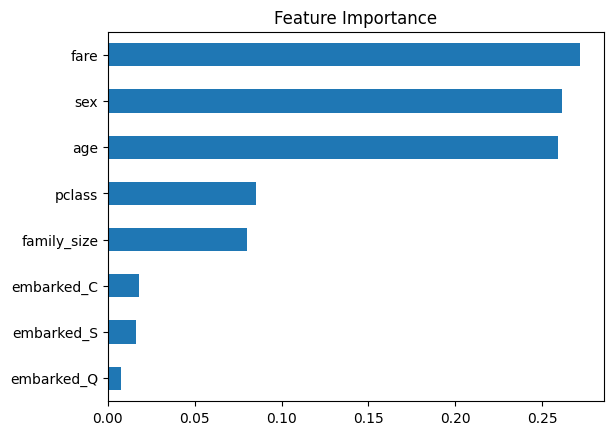

In [ ]:
# How much each feature contributed to the Random Forest's decisions
importances = pd.Series(rf2.feature_importances_, index=features2)
importances = importances.sort_values(ascending=False)
print(importances)

# Bar chart
importances.plot(kind='barh', title='Feature Importance')
plt.gca().invert_yaxis()
plt.show()

## Step 11: Predictions for new passengers
Tested the model on two example passengers.

In [ ]:
# A 30-year-old woman, 1st class, fare 80, travelling alone, boarded at Cherbourg
new_passenger = pd.DataFrame([{
    'pclass': 1, 'sex': 1, 'age': 30, 'fare': 80, 'family_size': 1,
    'embarked_C': 1, 'embarked_Q': 0, 'embarked_S': 0
}])

print(rf2.predict(new_passenger))
print(rf2.predict_proba(new_passenger))

[1]
[[0.03 0.97]]


In [ ]:
# A 25-year-old man, 3rd class, fare 7.5, travelling alone, boarded at Southampton
test2 = pd.DataFrame([{
    'pclass': 3, 'sex': 0, 'age': 25, 'fare': 7.5, 'family_size': 1,
    'embarked_C': 0, 'embarked_Q': 0, 'embarked_S': 1
}])

print(rf2.predict(test2))
print(rf2.predict_proba(test2))

[0]
[[0.96 0.04]]


## Step 12: Save the Model

Saved the trained Random Forest and its feature list so they can be reused later without training again.

In [ ]:
# Save the model and the feature list it expects
joblib.dump(rf2, 'titanic_model.pkl')
joblib.dump(features2, 'titanic_features.pkl')

print("Model saved!")

Model saved!


## Step 13: Model Performance Summary & Conclusion

### Model Comparison
We trained and evaluated two classical Machine Learning models to predict Titanic passenger survival using a 70% training and 30% testing split.

| Model | Metric | Initial Features | Improved Features (with Embarked & Family Size) | 5-Fold Cross-Validation (Average Accuracy) |
| :--- | :--- | :--- | :--- | :--- |
| **Logistic Regression** | **Accuracy**<br>Precision<br>Recall<br>F1-Score | **81.3%**<br>81.4%<br>71.2%<br>76.0% | **80.6%**<br>-<br>-<br>- | **79.0%** |
| **Random Forest** | **Accuracy**<br>Precision<br>Recall<br>F1-Score | **78.4%**<br>75.2%<br>71.2%<br>73.1% | **77.6%**<br>-<br>-<br>- | **80.6%** |

### Key Findings & Explanations
1. **Model Performance**: On the single 70/30 train/test split, **Logistic Regression** achieved a higher accuracy (**81.3%**) compared to the **Random Forest** (**78.4%**).
2. **Feature Engineering Impact**: Incorporating engineered features like `family_size` and one-hot encoded `embarked` variables slightly decreased the single-split test accuracy for both models, likely due to noise or overfitting on the small test set. However, robust **5-Fold Cross-Validation** revealed that **Random Forest** is overall the more reliable model, maintaining an average cross-validated accuracy of **80.6%** compared to **79.0%** for Logistic Regression.
3. **Feature Importance**: Based on our Random Forest feature importances, the top three predictive indicators of survival were:
   - **Fare** (27.2%)
   - **Sex** (26.2%)
   - **Age** (25.9%)
   
   This strongly aligns with historical records indicating that women and wealthier (higher class/higher fare paying) passengers had higher priority for lifeboats.

### Conclusion
All project milestones—from data acquisition, cleaning, preprocessing, exploratory visualization, model building, and metric-based evaluation—have been successfully completed in accordance with the minor project requirements.